In [1]:
import time
import seaborn as sns
import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.preprocessing import label_binarize

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

2025-07-03 23:35:26.403519: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-07-03 23:35:26.403569: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.


In [3]:
# Load the preprocessed dataset
df = pd.read_csv('../../../Edge-IIoTset_DNN-112.csv')

In [4]:
# Creating a dictionary of Types
attacks = {'Normal': 0,'MITM': 1, 'Uploading': 2, 'Ransomware': 3, 'SQL_injection': 4,
       'DDoS_HTTP': 5, 'DDoS_TCP': 6, 'Password': 7, 'Port_Scanning': 8,
       'Vulnerability_scanner': 9, 'Backdoor': 10, 'XSS': 11, 'Fingerprinting': 12,
       'DDoS_UDP': 13, 'DDoS_ICMP': 14}
df['Attack_type'] = df['Attack_type'].map(attacks)

In [5]:
X = df.drop(columns=['Attack_label', 'Attack_type'])
y = df['Attack_type']

In [6]:
# Load precomputed selected features
feature_list_path = "selected_features_15class_mi.pkl"
with open(feature_list_path, "rb") as f:
    selected_features = pickle.load(f)

In [20]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.125, random_state=42)

In [21]:
print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)

X_train shape: (1361814, 97)
X_val shape: (194545, 97)
X_test shape: (389090, 97)


In [22]:
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [23]:
def cnn_model(input_shape, num_classes):
    model = Sequential([
        Conv1D(32, 3, activation='relu', input_shape=input_shape),
        MaxPooling1D(pool_size=2),
        Conv1D(64, 3, activation='relu'),
        MaxPooling1D(pool_size=2),
        Conv1D(128, 3, activation='relu'),
        MaxPooling1D(pool_size=2),
        Conv1D(128, 3, activation='relu'),
        MaxPooling1D(pool_size=2),
        Conv1D(256, 3, activation='relu'),
        MaxPooling1D(pool_size=2),
        Flatten(),
        Dense(64, activation='relu'),
        Dense(num_classes, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

In [24]:
input_shape = (X_train.shape[1], 1)
num_classes = 15
model = cnn_model(input_shape, num_classes)
model.summary()

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv1d_15 (Conv1D)          (None, 95, 32)            128       
                                                                 
 max_pooling1d_15 (MaxPoolin  (None, 47, 32)           0         
 g1D)                                                            
                                                                 
 conv1d_16 (Conv1D)          (None, 45, 64)            6208      
                                                                 
 max_pooling1d_16 (MaxPoolin  (None, 22, 64)           0         
 g1D)                                                            
                                                                 
 conv1d_17 (Conv1D)          (None, 20, 128)           24704     
                                                                 
 max_pooling1d_17 (MaxPoolin  (None, 10, 128)         

In [27]:
early_stop = EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
)
model_checkpoint = ModelCheckpoint("CNN_15" + '.h5',
                     monitor='val_accuracy',
                     mode='max',
                     verbose=1,
                     save_best_only=True)

In [28]:
train_start_time = time.time()
# Train the model
history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=5,
                    batch_size=64,
                    callbacks=[early_stop, model_checkpoint])

# Record the ending time
train_end_time = time.time()

# Record the starting time for testing
test_start_time = time.time()
# Evaluate the model
loss, accuracy = model.evaluate(X_test, y_test, batch_size=64)
# Record the ending time for testing
test_end_time = time.time()

print(f'Test Loss: {loss:.4f}')
print(f'Test Accuracy: {accuracy:.4f}')

# Calculate and print the training time
train_time = train_end_time - train_start_time
print(f"Training time: {train_time:.2f} seconds")

# Calculate and print the testing time
test_time = test_end_time - test_start_time
print(f"Testing time: {test_time:.2f} seconds")

2025-07-03 23:49:43.209199: W tensorflow/core/framework/cpu_allocator_impl.cc:82] Allocation of 528383832 exceeds 10% of free system memory.


Epoch 1/5
21278/21279 [============================>.] - ETA: 0s - loss: 0.0940 - accuracy: 0.9580
Epoch 00001: val_accuracy improved from -inf to 0.96471, saving model to CNN_15.h5
21279/21279 [==============================] - 617s 29ms/step - loss: 0.0940 - accuracy: 0.9580 - val_loss: 0.0755 - val_accuracy: 0.9647
Epoch 2/5
21278/21279 [============================>.] - ETA: 0s - loss: 0.0755 - accuracy: 0.9643
Epoch 00002: val_accuracy did not improve from 0.96471
21279/21279 [==============================] - 400s 19ms/step - loss: 0.0755 - accuracy: 0.9643 - val_loss: 0.0810 - val_accuracy: 0.9630
Epoch 3/5
21276/21279 [============================>.] - ETA: 0s - loss: 0.0719 - accuracy: 0.9663
Epoch 00003: val_accuracy improved from 0.96471 to 0.96767, saving model to CNN_15.h5
21279/21279 [==============================] - 387s 18ms/step - loss: 0.0719 - accuracy: 0.9664 - val_loss: 0.0655 - val_accuracy: 0.9677
Epoch 4/5
21278/21279 [============================>.] - ETA: 0s 

In [29]:
n_samples = min(100, len(X_test))
total_time = 0.0

for i in range(n_samples):
    sample = X_test[i].reshape(1, -1, 1)  # Shape: (1, features, 1)
    start_time = time.time()
    _ = model.predict(sample, verbose=0)
    total_time += time.time() - start_time

avg_inference_time = total_time / n_samples
print(f"Average inference time per sample: {avg_inference_time:.6f} seconds")

Average inference time per sample: 0.114128 seconds


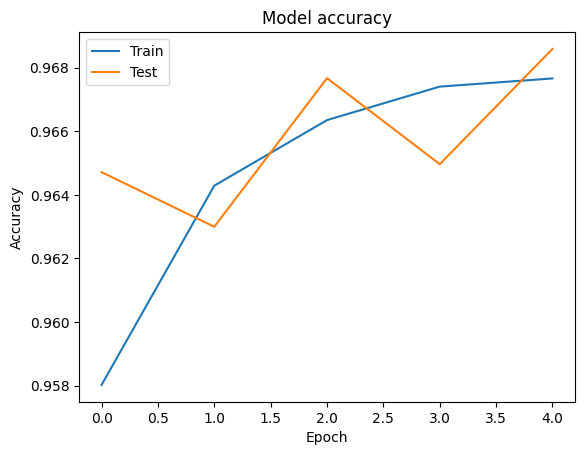

In [30]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

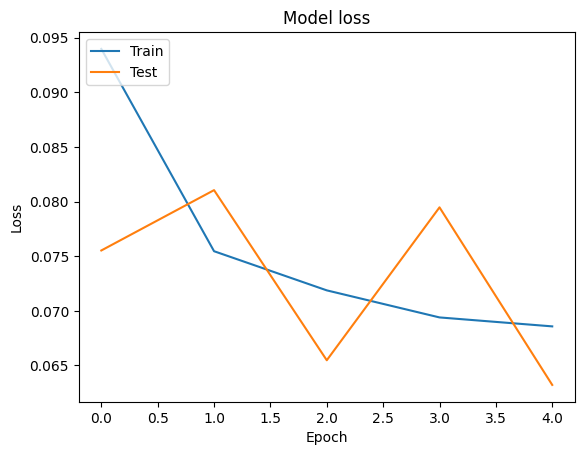

In [31]:
# Plot the training and validation loss over the epochs
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()
# plt.savefig('los_plo.jpg')

In [32]:
y_pred = model.predict(np.expand_dims(X_test, axis=2))

In [33]:
y_pred_classes = np.argmax(y_pred, axis=1)

# Inverse the 'attacks' dictionary to map back numbers to names
inverse_attacks = {v: k for k, v in attacks.items()}

# Generate the classification report with attack names instead of numbers
class_report = classification_report(y_test, y_pred_classes, target_names=[inverse_attacks[i] for i in range(len(inverse_attacks))])

print(class_report)

                       precision    recall  f1-score   support

               Normal       1.00      1.00      1.00    280115
                 MITM       1.00      1.00      1.00        69
            Uploading       0.92      0.64      0.76      7588
           Ransomware       1.00      0.92      0.95      2012
        SQL_injection       0.56      1.00      0.71     10041
            DDoS_HTTP       0.90      0.93      0.91      9620
             DDoS_TCP       0.98      0.94      0.96     10052
             Password       0.88      0.37      0.52      9869
        Port_Scanning       0.86      0.98      0.92      3985
Vulnerability_scanner       0.99      0.92      0.96      9985
             Backdoor       0.98      0.98      0.98      4883
                  XSS       0.65      0.73      0.69      3073
       Fingerprinting       0.93      0.39      0.55       171
             DDoS_UDP       1.00      1.00      1.00     24316
            DDoS_ICMP       0.99      1.00      1.00  

In [34]:
# Get detailed report as a dictionary
report_dict = classification_report(
    y_test,
    y_pred_classes,
    target_names=[inverse_attacks[i] for i in range(len(inverse_attacks))],
    output_dict=True
)

# Convert to DataFrame and format with more floats
report_df = pd.DataFrame(report_dict).T  # transpose for better layout
report_df = report_df.round(4)  # round to 4 decimal places

print(report_df)

                       precision  recall  f1-score      support
Normal                    1.0000  1.0000    1.0000  280115.0000
MITM                      1.0000  1.0000    1.0000      69.0000
Uploading                 0.9188  0.6444    0.7576    7588.0000
Ransomware                0.9968  0.9160    0.9547    2012.0000
SQL_injection             0.5557  0.9999    0.7144   10041.0000
DDoS_HTTP                 0.8985  0.9295    0.9138    9620.0000
DDoS_TCP                  0.9770  0.9364    0.9563   10052.0000
Password                  0.8832  0.3678    0.5194    9869.0000
Port_Scanning             0.8603  0.9824    0.9173    3985.0000
Vulnerability_scanner     0.9913  0.9229    0.9559    9985.0000
Backdoor                  0.9756  0.9828    0.9792    4883.0000
XSS                       0.6539  0.7299    0.6898    3073.0000
Fingerprinting            0.9296  0.3860    0.5455     171.0000
DDoS_UDP                  0.9999  1.0000    0.9999   24316.0000
DDoS_ICMP                 0.9939  0.9995

In [35]:
# Binarize the true labels for multi-class AUC
y_test_bin = label_binarize(y_test, classes=list(attacks.values()))  # shape: (n_samples, n_classes)

# y_pred is already the softmax output: shape (n_samples, n_classes)
auc_macro = roc_auc_score(y_test_bin, y_pred, average='macro', multi_class='ovr')
auc_weighted = roc_auc_score(y_test_bin, y_pred, average='weighted', multi_class='ovr')

print(f"AUC (macro-averaged OvR): {auc_macro:.4f}")
print(f"AUC (weighted-averaged OvR): {auc_weighted:.4f}")

AUC (macro-averaged OvR): 0.9983
AUC (weighted-averaged OvR): 0.9995


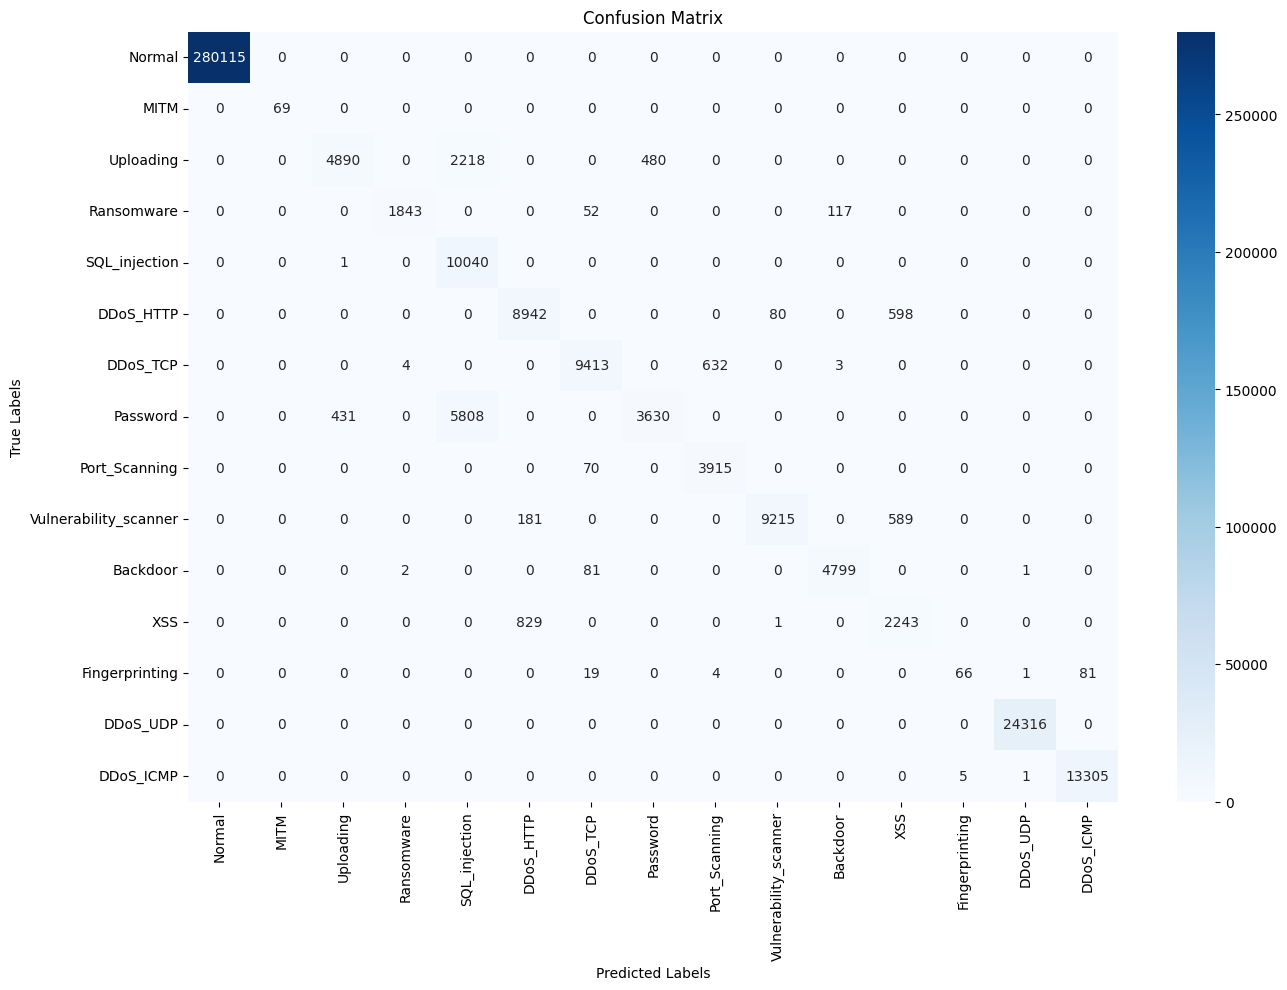

In [36]:
# Compute the confusion matrix
conf_mat = confusion_matrix(y_test, y_pred_classes)

# Convert the 'attacks' dictionary to a list of class names ordered by the class number
class_names_ordered = [attack for attack, number in sorted(attacks.items(), key=lambda item: item[1])]

# Plot the heatmap using seaborn
plt.figure(figsize=(15, 10))
sns.heatmap(conf_mat, annot=True, fmt="d", cmap="Blues", xticklabels=class_names_ordered, yticklabels=class_names_ordered)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
# plt.savefig('con_mat.jpg')

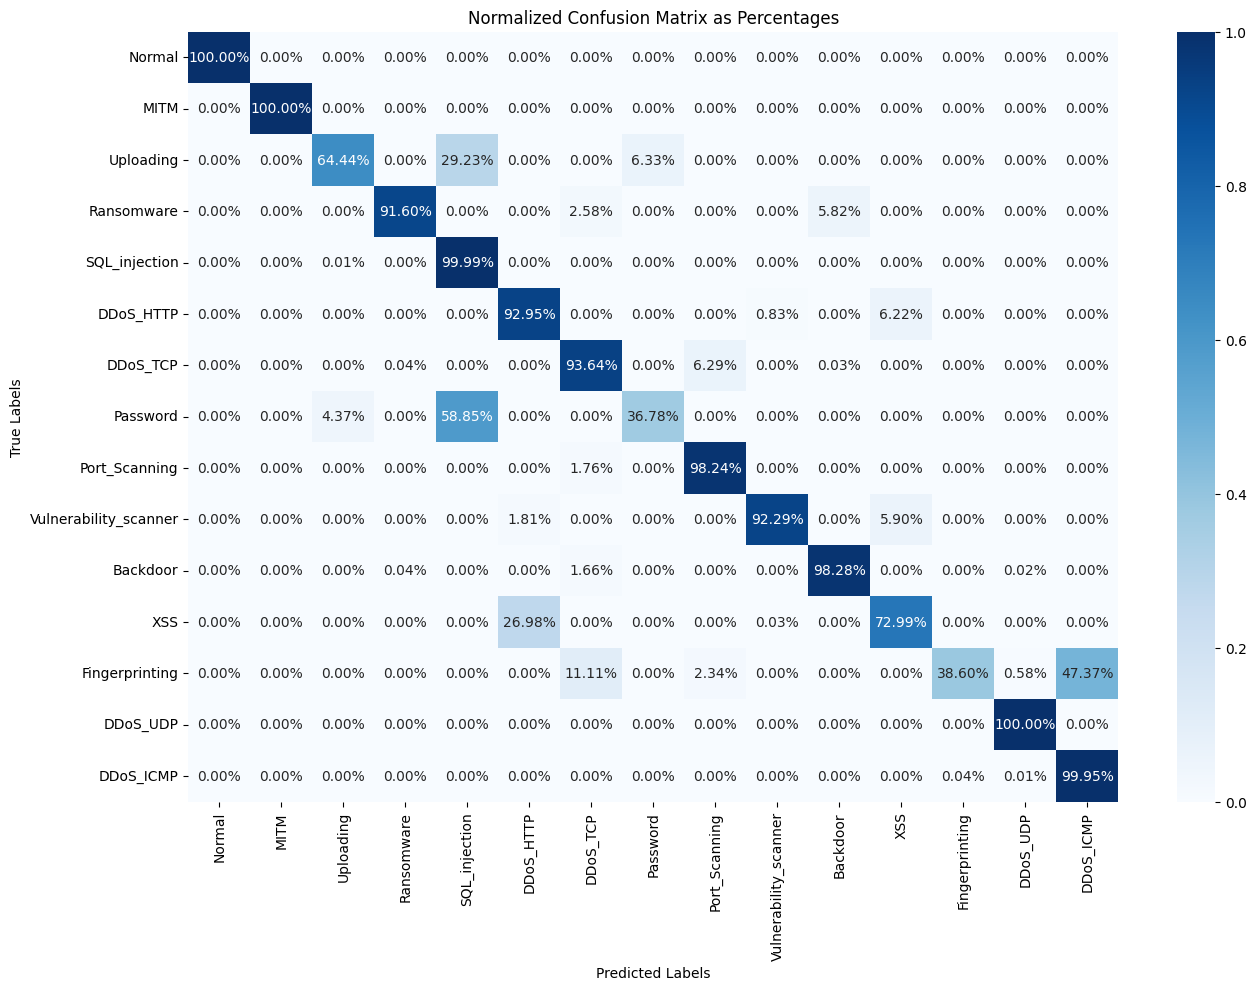

In [37]:
# Compute the confusion matrix
conf_mat = confusion_matrix(y_test, y_pred_classes)

# Normalize the confusion matrix by dividing each value by the sum of its row (i.e., the number of true instances for each label)
conf_mat_normalized = conf_mat.astype('float') / conf_mat.sum(axis=1)[:, np.newaxis]

# Convert the 'attacks' dictionary to a list of class names ordered by the class number
class_names_ordered = [attack for attack, number in sorted(attacks.items(), key=lambda item: item[1])]

# Plot the heatmap using seaborn
plt.figure(figsize=(15, 10))
sns.heatmap(conf_mat_normalized, annot=True, fmt=".2%", cmap="Blues", xticklabels=class_names_ordered, yticklabels=class_names_ordered)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Normalized Confusion Matrix as Percentages')
plt.show()
# plt.savefig('con_per.jpg')